# Self-RAG over the Orbitra knowledge base - Stage 3

Notebook version of `main.py`, split into sections. Run the cells top to bottom.

```
question -> decide_retrieval -> (yes) retrieve -> grade_documents -> (some relevant) generate -> answer
                                                                  -> (none relevant) no_relevant_docs -> answer
                             -> (no)  generate_direct -> answer
```

## Setup: imports, `.env`, paths

In [1]:
from pathlib import Path
from typing import Literal, TypedDict

import yaml
from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_community.embeddings import FastEmbedEmbeddings
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

load_dotenv()

DOCS_DIR = Path("documents")
MODELS_DIR = "models"
CHROMA_DIR = "chroma_db"
COLLECTION = "orbitra_kb"

/tmp/ipykernel_141474/3777396506.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import FastEmbedEmbeddings


## 1. Load the documents
Each `.md` file's YAML front-matter (`doc_id`, `status`, `applies_to`, ...) becomes the chunk's metadata.

In [2]:
# load the documents and parse the YAML header functions
def parse_markdown(path: Path) -> Document:
    """Read one .md file and turn its YAML front-matter into metadata."""
    text = path.read_text(encoding="utf-8")
    metadata = {"source": str(path)}

    if text.startswith("---"):
        _, front_matter, text = text.split("---", 2)
        try:
            header = yaml.safe_load(front_matter)
        except yaml.YAMLError:
            # e.g. HR-POSH-001 has an unquoted ": " inside a value, so read plain "key: value" lines
            lines = [line.split(":", 1) for line in front_matter.strip().splitlines() if ":" in line]
            header = {k.strip(): v.strip() for k, v in lines}
        for key, value in header.items():
            if value is None:
                continue
            # Chroma only stores str/int/float/bool, so flatten lists and dates
            if isinstance(value, list):
                value = ", ".join(map(str, value))
            elif not isinstance(value, (str, int, float, bool)):
                value = str(value)
            metadata[key] = value

    return Document(page_content=text.strip(), metadata=metadata)


def load_documents() -> list[Document]:
    return [parse_markdown(p) for p in sorted(DOCS_DIR.rglob("*.md"))]

splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)

## 2. Embeddings and vectorstore
Built once into `chroma_db/`, then loaded. Small `batch_size` keeps RAM low.

In [3]:
# ONNX model, downloaded into models/ on the first run (bge vectors come out normalized).
# batch_size: default is 256, which needs >1.5 GB RAM for these chunks and froze the laptop.
embeddings = FastEmbedEmbeddings(model_name="BAAI/bge-small-en-v1.5", cache_dir=MODELS_DIR, batch_size=16)


# embeddings and the vectorstore (build once, and then load)
def get_vectorstore() -> Chroma:
    """Load the saved Chroma DB, or (re)build it if it is missing or incomplete."""
    vectorstore = Chroma(
        collection_name=COLLECTION,
        embedding_function=embeddings,
        persist_directory=CHROMA_DIR,
    )
    chunks = splitter.split_documents(load_documents())

    # fewer chunks than expected means first run, or an earlier build crashed halfway
    stored = len(vectorstore.get(include=[])["ids"])
    if stored == len(chunks):
        return vectorstore
    if stored:
        print(f"Vectorstore is incomplete ({stored}/{len(chunks)} chunks), rebuilding...")
        vectorstore.reset_collection()

    print(f"Building vectorstore from {len(chunks)} chunks...")
    step = embeddings.batch_size
    for i in range(0, len(chunks), step):
        vectorstore.add_documents(chunks[i:i + step])
        print(f"\r  embedded {min(i + step, len(chunks))}/{len(chunks)} chunks", end="", flush=True)
    print()
    return vectorstore


vectorstore = get_vectorstore()
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

/media/kmh/New Volume/GenAICampusX/LangGraph/SelfRAG/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. LLMs and the answer prompt
`llm` writes answers; `judge_llm` (low reasoning effort) makes the yes/no judgments.

In [4]:
# llm and prompt
# max_retries: on a 429 (free tier is 8000 tokens/min) the client waits as Groq says, then retries
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_retries=6)
# yes/no judgments don't need deep thinking; fewer reasoning tokens = fewer rate-limit hits.
# set on the model itself: llm.bind(reasoning_effort=...) is dropped by with_structured_output
judge_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_retries=6, reasoning_effort="low")

prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are OrbitBot, an internal assistant for Orbitra Technologies employees. "
     "Answer the question using only the context below. If the context does not "
     "contain the answer, say you don't know. If the answer depends on details the "
     "user did not give (location, level, etc.), list the options from the context "
     "and ask which applies. Cite the doc_id of every source you use, like "
     "[HR-LV-001].\n\nContext:\n{context}"),
    ("human", "{question}"),
])

def format_docs(docs: list[Document]) -> str:
    return "\n\n".join(f"[{d.metadata.get('doc_id', '?')}] {d.page_content}" for d in docs)

## 4. Stage 2 - retrieval decision (Self-RAG *Retrieve*)
Structured output: the LLM returns a `RetrievalDecision` object, not free text.

In [5]:
# retrieval decision (Self-RAG's "Retrieve" step), returned as a Pydantic object
class RetrievalDecision(BaseModel):
    """Decide whether the question needs Orbitra's knowledge base."""
    should_retrieve: bool = Field(description="True if answering needs Orbitra's internal documents "
        "(policies, processes, people, products, company facts); False for greetings, small talk, "
        "or general knowledge unrelated to Orbitra.")
    reason: str = Field(description="One short sentence explaining the decision.")


decide_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You decide whether a question to OrbitBot, the internal assistant of Orbitra Technologies, "
     "needs a search of the company knowledge base (HR, IT, security, finance, admin, legal, "
     "engineering, product and sales documents). Retrieve for anything about Orbitra or how things "
     "work there, even if it sounds general (e.g. 'how do I reset my password?'). Do not retrieve "
     "for greetings, thanks, small talk, or general knowledge unrelated to Orbitra. When unsure, retrieve."),
    ("human", "{question}"),
])
decider = decide_prompt | judge_llm.with_structured_output(RetrievalDecision)

direct_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are OrbitBot, an internal assistant for Orbitra Technologies employees. Answer briefly. "
     "This question was judged not to need company documents, so do not state any Orbitra-specific "
     "facts or policies; if the user needs those, suggest they ask about them directly."),
    ("human", "{question}"),
])

## 5. Stage 3 - document grading (Self-RAG *IsRel*)
One `DocGrade` per retrieved chunk; the grader sees the chunk's metadata too.

In [6]:
# document grading (Self-RAG's "IsRel" step), one grade per retrieved chunk
class DocGrade(BaseModel):
    """Relevance grade for one retrieved chunk."""
    is_relevant: bool = Field(description="True if the chunk contains information that helps answer "
        "the question; False if it is off-topic, superseded, or for a different region or group "
        "than the question asks about.")
    reason: str = Field(description="One short sentence explaining the grade.")


grade_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You grade whether a chunk from Orbitra's knowledge base is relevant to an employee's question. "
     "Use the chunk's metadata: a chunk with status 'superseded' is never relevant, because a newer "
     "version exists. A chunk whose applies_to clearly excludes the region or group the question is "
     "about is not relevant. If the question names no region, any region can be relevant. Otherwise "
     "be lenient: the chunk only needs to contain part of the answer."),
    ("human",
     "Question: {question}\n\nChunk metadata: doc_id={doc_id}, title={title}, status={status}, "
     "applies_to={applies_to}\n\nChunk:\n{chunk}"),
])
grader = grade_prompt | judge_llm.with_structured_output(DocGrade)

## 6. Graph state, nodes and routers
Nodes return state updates; routers only read the state and name the next node.

In [7]:
# the graph(state,nodes,edges)
class GraphState(TypedDict):
    question: str
    should_retrieve: bool
    retrieval_reason: str
    documents: list[Document]
    doc_grades: list[dict]
    answer: str


def decide_retrieval(state: GraphState) -> dict:
    decision = decider.invoke({"question": state["question"]})
    return {"should_retrieve": decision.should_retrieve, "retrieval_reason": decision.reason}


# router, not a node: only reads the state and names the next node
def route_after_decision(state: GraphState) -> Literal["retrieve", "generate_direct"]:
    return "retrieve" if state["should_retrieve"] else "generate_direct"


def retrieve(state: GraphState) -> dict:
    docs = retriever.invoke(state["question"])
    return {"documents": docs}


def grade_documents(state: GraphState) -> dict:
    docs = state["documents"]
    grades = grader.batch([
        {"question": state["question"], "chunk": d.page_content,
         **{k: d.metadata.get(k, "?") for k in ("doc_id", "title", "status", "applies_to")}}
        for d in docs
    ])  # one LLM call per chunk, sent in parallel
    # no reducer on "documents", so this filtered list replaces the one retrieve wrote
    return {
        "documents": [d for d, g in zip(docs, grades) if g.is_relevant],
        "doc_grades": [{"doc_id": d.metadata.get("doc_id"), "relevant": g.is_relevant, "reason": g.reason}
                       for d, g in zip(docs, grades)],
    }


def route_after_grading(state: GraphState) -> Literal["generate", "no_relevant_docs"]:
    return "generate" if state["documents"] else "no_relevant_docs"


def no_relevant_docs(state: GraphState) -> dict:
    return {"answer": "I couldn't find anything in the Orbitra knowledge base that answers this. "
                      "Try rephrasing, or raise an OrbitDesk ticket with the relevant team."}


def generate(state: GraphState) -> dict:
    chain = prompt | llm
    response = chain.invoke({
        "context": format_docs(state["documents"]),
        "question": state["question"],
    })
    return {"answer": response.content}


def generate_direct(state: GraphState) -> dict:
    response = (direct_prompt | llm).invoke({"question": state["question"]})
    return {"answer": response.content}

## 7. Build the graph

In [8]:
builder = StateGraph(GraphState)
builder.add_node("decide_retrieval", decide_retrieval)
builder.add_node("retrieve", retrieve)
builder.add_node("grade_documents", grade_documents)
builder.add_node("generate", generate)
builder.add_node("no_relevant_docs", no_relevant_docs)
builder.add_node("generate_direct", generate_direct)
builder.add_edge(START, "decide_retrieval")
builder.add_conditional_edges("decide_retrieval", route_after_decision)
builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges("grade_documents", route_after_grading)
builder.add_edge("generate", END)
builder.add_edge("no_relevant_docs", END)
builder.add_edge("generate_direct", END)
app = builder.compile()

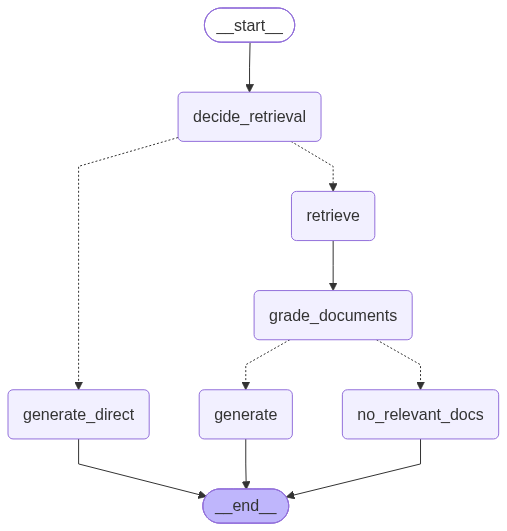

In [9]:
app

## 8. Ask questions
`ask()` streams each node's update so you can watch the decision and the grades. (The interactive loop is in `main.py`: `uv run main.py`.)

In [10]:
def ask(question: str):
    for step in app.stream({"question": question}, stream_mode="updates"):
        for node, update in step.items():
            print(f"--- {node} ---")
            if node == "decide_retrieval":
                print(f"  retrieve={update['should_retrieve']}  ({update['retrieval_reason']})")
            elif node == "retrieve":
                for d in update["documents"]:
                    print(f"  [{d.metadata.get('doc_id')}] status={d.metadata.get('status')}  "
                          f"{d.page_content[:80]!r}")
            elif node == "grade_documents":
                for g in update["doc_grades"]:
                    print(f"  {'✓' if g['relevant'] else '✗'} [{g['doc_id']}] {g['reason']}")
            else:
                print(update["answer"])

In [11]:
ask("hi")

--- decide_retrieval ---
  retrieve=False  (User greeting does not require internal knowledge.)
--- generate_direct ---
Hello! How can I help you today?


In [12]:
ask("How many days of paternity leave can I take in Bengaluru?")

--- decide_retrieval ---
  retrieve=True  (User asks about paternity leave policy for Bengaluru, which is internal HR policy.)
--- retrieve ---
  [HR-LV-002] status=active  '## Parental leave\n- **16 weeks fully paid** for birthing parents (includes short'
  [HR-LV-001] status=superseded  '# Leave Policy – India (v4.0) — ARCHIVED / SUPERSEDED\n\n> ⚠️ This version is reta'
  [HR-LV-001] status=active  '# Leave Policy – India (v5.0)\n\n> **What changed in v5.0 (effective 1 April 2026)'
  [HR-LV-003] status=active  '## Family leave\n- **Maternity / Adoption:** 26 weeks at full pay, followed by 13'
--- grade_documents ---
  ✗ [HR-LV-002] The chunk covers US parental leave policy and applies only to United States employees, not Bengaluru.
  ✗ [HR-LV-001] The chunk is marked superseded, so it should not be used to answer current questions.
  ✓ [HR-LV-001] Chunk specifies paternity leave is 10 working days for India including Bengaluru, directly answering the question.
  ✗ [HR-LV-003] The chu

In [13]:
ask("How many sick leaves do India employees get per year?")

--- decide_retrieval ---
  retrieve=True  (Question asks about specific company policy (sick leave entitlement) for India employees, requiring internal HR documents.)
--- retrieve ---
  [HR-LV-001] status=superseded  '# Leave Policy – India (v4.0) — ARCHIVED / SUPERSEDED\n\n> ⚠️ This version is reta'
  [HR-LV-003] status=active  '# Annual Leave and Absence Policy – UK\n\n## Annual leave\n- **25 days** annual lea'
  [HR-LV-001] status=active  '# Leave Policy – India (v5.0)\n\n> **What changed in v5.0 (effective 1 April 2026)'
  [HR-HOL-2026] status=active  '# Holiday Calendar 2026 – India\n\nIndia employees get **10 fixed holidays** (loca'
--- grade_documents ---
  ✗ [HR-LV-001] The chunk is marked superseded, so it should not be used to answer current questions.
  ✗ [HR-LV-003] The chunk pertains to UK employees and does not address sick leave entitlements for India employees.
  ✗ [HR-LV-001] Chunk discusses general leave policy changes but does not provide the number of sick leaves fo